<a href="https://colab.research.google.com/github/gchekwemoi/OOP-python-assignment/blob/main/project3_fish_risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Portable setup for Anaconda/Jupyter and Google Colab
from pathlib import Path
import os
import sys
import subprocess

repo = Path.cwd().resolve()
if not (repo / "src").is_dir():
    colab_repo = Path("/content/OOP-python-assignment")
    if colab_repo.is_dir():
        repo = colab_repo
    elif "google.colab" in sys.modules or os.environ.get("COLAB_RELEASE_TAG"):
        subprocess.run(
            ["git", "clone", "https://github.com/gchekwemoi/OOP-python-assignment.git",
             str(colab_repo)], check=True
        )
        repo = colab_repo
    else:
        raise FileNotFoundError(
            "Open Jupyter from the OOP-python-assignment repository folder, "
            "which must contain the src/ and tests/ directories."
        )
os.chdir(repo)
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
print("Project directory:", repo)

# Check the project's automated tests
subprocess.run([sys.executable, "-m", "pytest", "tests/test_fish_model.py", "-v"], check=True)


Cloning into 'OOP-python-assignment'...
remote: Enumerating objects: 76, done.
remote: Counting objects: 100% (76/76), done.
remote: Compressing objects: 100% (67/67), done.
remote: Total 76 (delta 29), reused 2 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (76/76), 552.61 KiB | 9.06 MiB/s, done.
Resolving deltas: 100% (29/29), done.
/content/OOP-python-assignment
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/OOP-python-assignment
plugins: platformdirs-4.12.2, anyio-4.15.1, langsmith-0.14.2, typeguard-4.6.0
collected 10 items                                                             

tests/test_fish_model.py::test_fish_stock_simulation PASSED              [ 10%]
tests/test_fish_model.py::test_fish_growth_calculation PASSED            [ 20%]
tests/test_fish_model.py::test_invalid_harvest_rate PASSED               [ 3

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.fish_stock import FishStock
from src.price_model import PriceModel
from src.risk_assessor import RiskAssessor

# Create our OOP objects
fish_model = FishStock()
price_model = PriceModel(seed=42)
risk_model = RiskAssessor()

# Four harvesting scenarios from the assignment
harvest_rates = [0.05, 0.10, 0.20, 0.30]

# Simulate 52 weeks
weeks = 52
results = {}
summary_rows = []

# Generate weekly fish prices
prices = price_model.simulate(weeks=weeks)

for rate in harvest_rates:
    simulation = fish_model.simulate(
        harvest_rate=rate,
        weeks=weeks
    )

    stocks = simulation["stocks"]
    harvests = simulation["harvests"]

    # Calculate weekly revenue
    weekly_revenue = price_model.calculate_revenue(
        harvest_tonnes=harvests,
        prices=prices
    )

    # Assess revenue risk
    risk = risk_model.summarise(weekly_revenue)

    results[rate] = {
        "stocks": stocks,
        "harvests": harvests,
        "revenue": weekly_revenue,
        "risk": risk
    }

    summary_rows.append({
        "Harvest Rate": f"{rate:.0%}",
        "Final Stock (tonnes)": stocks[-1],
        "Total Revenue (UGX)": weekly_revenue.sum(),
        "Revenue CV (%)": risk["cv_percent"],
        "Risk Class": risk["risk_class"]
    })

# Display comparison
scenario_summary = pd.DataFrame(summary_rows)

print("LAKE VICTORIA FISH HARVESTING SCENARIOS")
display(scenario_summary.round(2))


LAKE VICTORIA FISH HARVESTING SCENARIOS


,Harvest Rate,Final Stock (tonnes),Total Revenue (UGX),Revenue CV (%),Risk Class
0,5%,8750.00,2.675193e+11,16.41,Moderate
1,10%,7500.00,4.602892e+11,15.24,Moderate
2,20%,4999.99,6.261529e+11,11.11,Moderate
3,30%,2503.72,5.195425e+11,11.59,Moderate


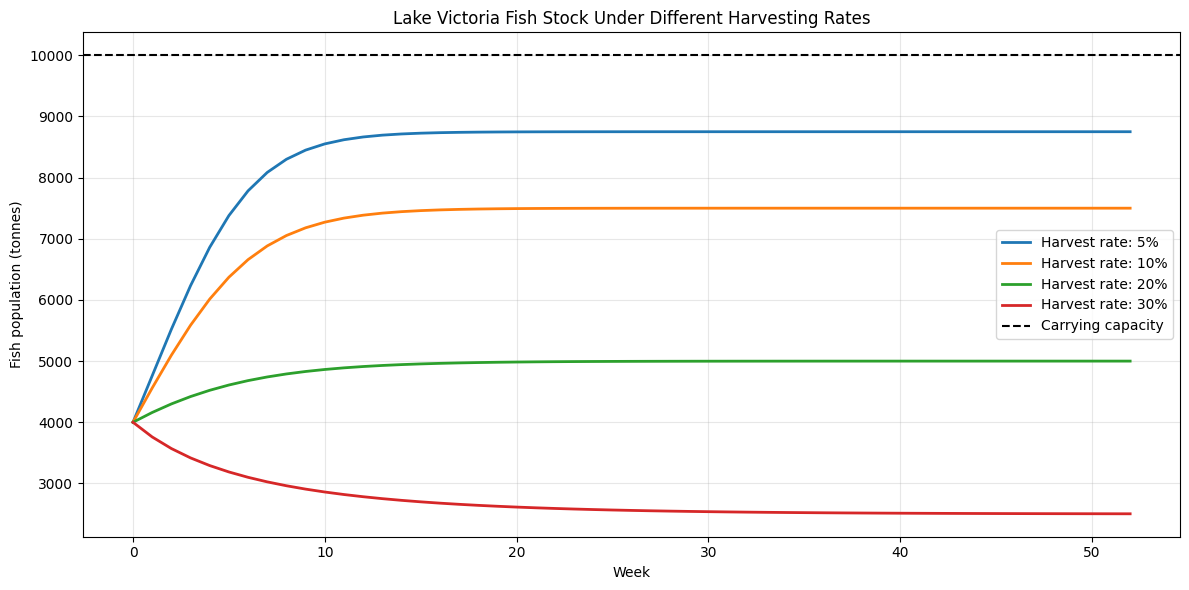

In [3]:

plt.figure(figsize=(12, 6))

for rate in harvest_rates:
    plt.plot(
        range(53),
        results[rate]["stocks"],
        label=f"Harvest rate: {rate:.0%}",
        linewidth=2
    )

plt.axhline(
    y=fish_model.carrying_capacity,
    color="black",
    linestyle="--",
    label="Carrying capacity"
)

plt.xlabel("Week")
plt.ylabel("Fish population (tonnes)")
plt.title("Lake Victoria Fish Stock Under Different Harvesting Rates")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [4]:

# Calculate theoretical Maximum Sustainable Yield
r = fish_model.growth_rate
K = fish_model.carrying_capacity

msy = r * K / 4

print("MAXIMUM SUSTAINABLE YIELD")
print(f"Growth rate: {r}")
print(f"Carrying capacity: {K:,.0f} tonnes")
print(f"Theoretical MSY: {msy:,.0f} tonnes per week")

# Compare average harvesting quantities across scenarios
msy_rows = []

for rate in harvest_rates:
    harvests = results[rate]["harvests"]

    msy_rows.append({
        "Harvest Rate": f"{rate:.0%}",
        "Average Weekly Harvest (tonnes)": harvests.mean(),
        "MSY (tonnes/week)": msy,
        "Above MSY": harvests.mean() > msy
    })

msy_summary = pd.DataFrame(msy_rows)

display(msy_summary.round(2))


MAXIMUM SUSTAINABLE YIELD
Growth rate: 0.4
Carrying capacity: 10,000 tonnes
Theoretical MSY: 1,000 tonnes per week


,Harvest Rate,Average Weekly Harvest (tonnes),MSY (tonnes/week),Above MSY
0,5%,417.59,1000.0,False
1,10%,718.51,1000.0,False
2,20%,978.30,1000.0,False
3,30%,816.56,1000.0,False


MONTE CARLO REVENUE RISK ANALYSIS
Number of simulations: 1,000
Average annual revenue: UGX 455,168,420,225
5th percentile annual revenue: UGX 370,674,359,144
Shortfall from average: UGX 84,494,061,082


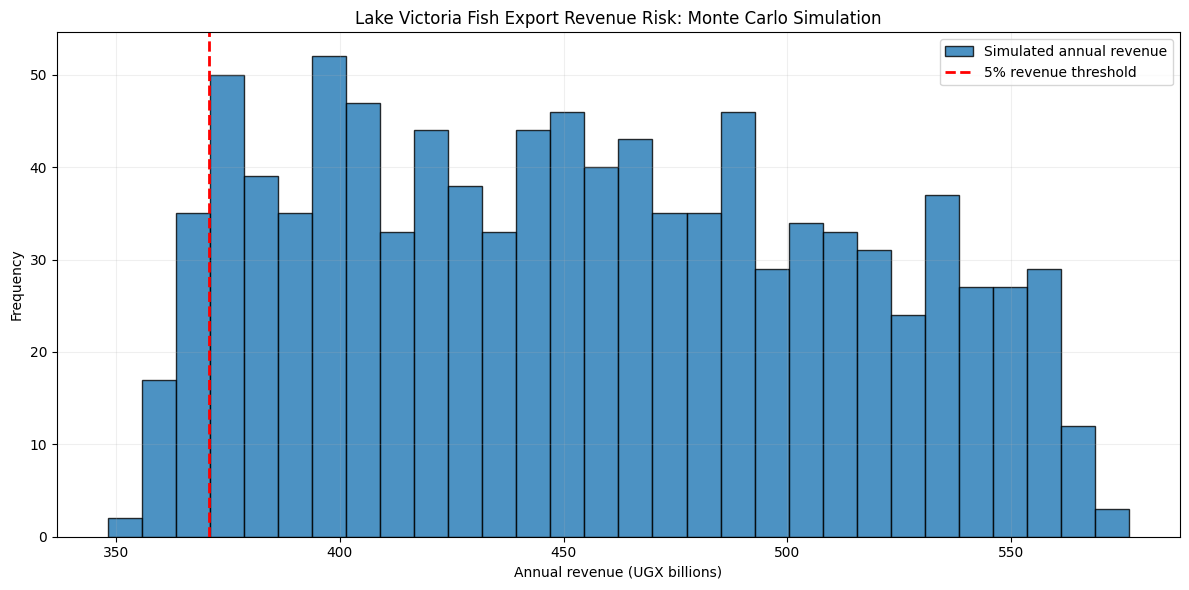

In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducible Monte Carlo simulation
simulations = 1000
annual_revenues = []

# Use the 10% harvesting scenario
baseline_harvests = results[0.10]["harvests"]

for seed in range(simulations):
    # Each seed generates a different price path
    model = PriceModel(seed=seed)

    simulated_prices = model.simulate(weeks=52)

    weekly_revenues = model.calculate_revenue(
        harvest_tonnes=baseline_harvests,
        prices=simulated_prices
    )

    annual_revenues.append(weekly_revenues.sum())

annual_revenues = np.array(annual_revenues)

# Calculate revenue risk
var_results = risk_model.value_at_risk(annual_revenues)

print("MONTE CARLO REVENUE RISK ANALYSIS")
print(f"Number of simulations: {simulations:,}")

print(
    f"Average annual revenue: "
    f"UGX {var_results['mean_annual_revenue']:,.0f}"
)

print(
    f"5th percentile annual revenue: "
    f"UGX {var_results['revenue_5th_percentile']:,.0f}"
)

print(
    f"Shortfall from average: "
    f"UGX {var_results['shortfall_from_mean']:,.0f}"
)

# Visualise annual revenue outcomes
plt.figure(figsize=(12, 6))

plt.hist(
    annual_revenues / 1e9,
    bins=30,
    edgecolor="black",
    alpha=0.8,
    label="Simulated annual revenue"
)

plt.axvline(
    var_results["revenue_5th_percentile"] / 1e9,
    color="red",
    linestyle="--",
    linewidth=2,
    label="5% revenue threshold"
)

plt.xlabel("Annual revenue (UGX billions)")
plt.ylabel("Frequency")
plt.title("Lake Victoria Fish Export Revenue Risk: Monte Carlo Simulation")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


FIVE-YEAR CLOSED-SEASON COMPARISON


,Measure,Continuous harvesting,Eight-week closure,Difference
0,Total harvest (tonnes),1.933625e+05,1.683285e+05,-2.503399e+04
1,Total revenue (UGX),2.182771e+12,1.909376e+12,-2.733952e+11
2,Final fish stock (tonnes),7.500000e+03,7.500000e+03,0.000000e+00


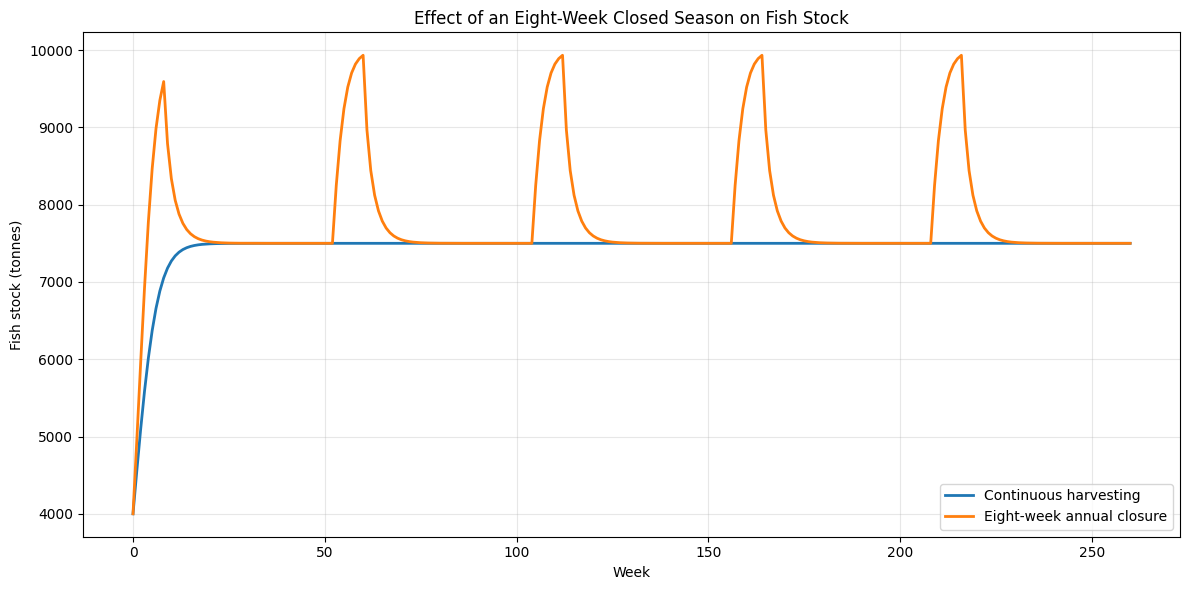

In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Five years of weekly simulation
weeks = 260
harvest_rate = 0.10
closed_weeks = 8

def simulate_fishing(closed_season=False):
    """Simulate fish stocks and harvesting for five years."""

    stock = fish_model.initial_stock
    stocks = [stock]
    harvests = []

    for week in range(weeks):
        # Close fishing for the first 8 weeks of each year
        week_of_year = week % 52

        if closed_season and week_of_year < closed_weeks:
            current_harvest_rate = 0.0
        else:
            current_harvest_rate = harvest_rate

        harvest = current_harvest_rate * stock

        growth = (
            fish_model.growth_rate
            * stock
            * (1 - stock / fish_model.carrying_capacity)
        )

        stock = max(0.0, stock + growth - harvest)

        harvests.append(harvest)
        stocks.append(stock)

    return np.array(stocks), np.array(harvests)


# Compare the two scenarios
open_stocks, open_harvests = simulate_fishing(False)
closed_stocks, closed_harvests = simulate_fishing(True)

# Use the same simulated prices for a fair comparison
five_year_prices = PriceModel(seed=42).simulate(weeks=weeks)

open_revenue = (
    open_harvests * 1000 * five_year_prices
)

closed_revenue = (
    closed_harvests * 1000 * five_year_prices
)

# Summarise the differences
closed_season_summary = pd.DataFrame({
    "Measure": [
        "Total harvest (tonnes)",
        "Total revenue (UGX)",
        "Final fish stock (tonnes)"
    ],
    "Continuous harvesting": [
        open_harvests.sum(),
        open_revenue.sum(),
        open_stocks[-1]
    ],
    "Eight-week closure": [
        closed_harvests.sum(),
        closed_revenue.sum(),
        closed_stocks[-1]
    ]
})

closed_season_summary["Difference"] = (
    closed_season_summary["Eight-week closure"]
    - closed_season_summary["Continuous harvesting"]
)

print("FIVE-YEAR CLOSED-SEASON COMPARISON")
display(closed_season_summary.round(2))

# Compare fish population trajectories
plt.figure(figsize=(12, 6))

plt.plot(
    open_stocks,
    label="Continuous harvesting",
    linewidth=2
)

plt.plot(
    closed_stocks,
    label="Eight-week annual closure",
    linewidth=2
)

plt.xlabel("Week")
plt.ylabel("Fish stock (tonnes)")
plt.title("Effect of an Eight-Week Closed Season on Fish Stock")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:

# Generate 15 Fibonacci numbers
fibonacci = [0, 1]

while len(fibonacci) < 15:
    fibonacci.append(fibonacci[-1] + fibonacci[-2])

print("First 15 Fibonacci numbers:")
print(fibonacci)


First 15 Fibonacci numbers:
[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]


Fibonacci growth is not a realistic long-term model of fish populations because it assumes continued growth without considering resource limitations. In reality, fish populations are constrained by food availability, habitat, environmental conditions and harvesting pressure. A population cannot increase indefinitely in a lake with limited carrying capacity. The logistic growth model is more appropriate because it incorporates environmental limits and allows harvesting to reduce the stock.

## Findings & Limitations

This project developed a Python-based model to examine fish stock sustainability and revenue risk for a fish-export cooperative operating around Lake Victoria in Jinja. The analysis used logistic population growth with harvesting, a simulated fish-price model and statistical measures of revenue uncertainty.

Four harvesting rates (5%, 10%, 20% and 30%) were evaluated over 52 weeks. The simulations demonstrated how harvesting decisions influence fish population growth, annual revenue and financial risk. Higher harvesting rates can initially increase catches, but excessive harvesting may reduce future fish stocks and undermine long-term sustainability. The theoretical Maximum Sustainable Yield was estimated at 1,000 tonnes per week, although actual sustainable harvesting depends on population levels and environmental conditions.

The Monte Carlo analysis generated 1,000 possible annual revenue outcomes using simulated weekly prices. The fifth percentile of annual revenue was used to measure downside revenue risk. The coefficient of variation also helped compare revenue fluctuations across harvesting scenarios. Unlike raw variance, it provides a relative measure of volatility.

The five-year closed-season extension compared continuous harvesting with an eight-week annual fishing closure. This demonstrated how temporary fishing restrictions can influence stock recovery and long-term revenue, although their overall benefits depend on the simulation results.

**Limitations:** The model uses illustrative biological parameters and simulated fish prices rather than observed Lake Victoria data. It assumes constant growth conditions and harvesting rates, and excludes fish migration, illegal fishing, climate variability, fishing costs and changes in market demand. The Monte Carlo simulation captures price uncertainty but not uncertainty in fish stock growth or harvesting quantities. Consequently, the findings demonstrate useful modelling approaches rather than definitive policy recommendations.